# 04 신마법공식 (PBR + GP/A)

## 0. 원문 정리
> **책 원문 미확인 — 정의는 2차 인용, 나머지 설정은 우동호 설정을 따름.**
> 2차 출처도 파일로 찾지 못함(0단계 대조 2026-11-04: `마법공식_자료` PDF 전부에 '신마법'·'강환국' 0건, IBK 2020 리포트의 GPR은 매출총이익/(자산총계 − 현금 − 투자자산)이고 PBR과 묶지 않음). 이 정의(PBR 순위 + GP/A 순위)는 작업 지시 문서 `마법공식_백테스트\ClaudeCode_프롬프트_과제02_다음단계.md`에만 있다.
> 강환국(2017) 10장 원문이 없어 종목 수·리밸런싱·가중 같은 책의 숫자는 쓰지 않는다(지어내지 않음).

| 항목 | 정의 | 출처 | 우리 설정 |
|---|---|---|---|
| 지표 | PBR 순위(낮을수록 좋음) + GP/A 순위(높을수록 좋음) 합산 | 2차 인용 | `지표=[("BP","높게"),("GPA","높게")]`, `합산="순위합산"` |
| PBR | 시가총액 / 자기자본 | — | `BP` = 자본총계(지배) / 시가총액의 역수 꼴. 낮은 PBR = 높은 BP(자본이 음수인 종목만 순서가 다름 → 아래 '다르게 한 것') |
| GP/A | 매출총이익 / 자산총계 | Novy-Marx(2013), 우동호 p.513 | `GPA`(매출총이익 M000904007) |
| 나머지 | 우동호 외(2023) IMF와 똑같이(투자기구 제외만 원문에 없고 회원 결정 2026-11-01) | 우동호 p.512–513 | `포.우동호2023`: 유가+코스닥, 금융업·투자기구(원문에 없음)·12월 결산 아님·거래정지 제외, 4월 첫 거래일, 상위 30종목, 동일가중, 같은 거래비용(전량교체), 수정주가, 국고3년 |

참고(7절): Novy-Marx, NBER Working Paper 15940(2010년 4월판, 파일 이름은 2013이지만 표지는 April 2010. 학술지판 2013 JFE의 표 번호는 확인 안 함) 4.3.1절·표 7 Panel C 설정(비금융 대형주 500, GP/A + B/M 순위 평균, 3묶음, 6월 말 연 1회)으로도 돌려 원문 숫자와 비교한다.

줄임말: EW(동일가중, Equal Weight), VW(시가총액가중, Value Weight), LS(롱숏: 좋은 분위를 사고 나쁜 분위를 판 수익률),
MDD(최대 낙폭, Maximum Drawdown), IR(정보비율, Information Ratio), CAPM(자본자산가격결정모형), FF3(파마-프렌치 3요인), Carhart(카하트 4요인: FF3 + 모멘텀),
OLS(보통최소제곱), NW(뉴이-웨스트: 자기상관·이분산을 감안한 t), TR(배당 포함 수정주가).

## 1. 불러오기
계산은 모두 `공통/` 폴더의 모듈이 한다. 이 노트북은 설정을 정하고, 실행하고, 결과를 본다.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import numpy as np
import pandas as pd
import 데이터읽기 as 읽기, 종목거르기, 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 300)

## 2. 데이터 경로와 기간
데이터를 어디서 읽을지, 어느 기간을 돌릴지 정한다. 기간은 (첫 리밸런싱 월, 마지막 기준일 월)이다.

In [2]:
# 새로 통째로 받은 파일(읽기.DATA 기본 = data\통합_전체_202611, DataGuide 달력기준 일간)로 원문 기간을 돌린다.
기간 = ("2004-04", "2022-03")  # 01(우동호 p.512)과 같은 기간, 마지막 구간은 2022-03 마지막 거래일에서 끊음
print("데이터:", 읽기.DATA, "/ 기간:", 기간)

데이터: D:\26-2_데이터기반투자전략\과제02\data\통합_전체_202611 / 기간: ('2004-04', '2022-04')


## 3. 설정
신마법공식과, 같은 설정의 우동호 IMF(GP/A + EY)를 나란히 돌린다.

In [3]:
설정 = {"신마법공식": {**포.우동호2023, "이름": "신마법공식", "기간": 기간, "끝": "마지막거래일", "지표": [("BP", "높게"), ("GPA", "높게")]},
        "우동호IMF": {**포.우동호2023, "이름": "우동호2023_IMF", "기간": 기간, "끝": "마지막거래일", "지표": [("GPA", "높게"), ("EY", "높게")]}}
pd.DataFrame(설정).astype(str)

,신마법공식,우동호IMF
시장,"['KS', 'KQ']","['KS', 'KQ']"
가격,S410000700,S410000700
기간,"('2004-04', '2022-04')","('2004-04', '2022-04')"
기준일,첫거래일,첫거래일
리밸런싱,12,12
재무시점,"('결산후개월', 3)","('결산후개월', 3)"
제외,"['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래...","['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래..."
지표,"[('BP', '높게'), ('GPA', '높게')]","[('GPA', '높게'), ('EY', '높게')]"
합산,순위합산,순위합산
고르기,"('상위N', 30)","('상위N', 30)"


## 4. 실행: 상위 30종목, EW·VW
KOSPI 행의 알파·t는 시장을 자기 자신에 회귀한 값이라 뜻이 없다. '이상값 보유' = 보유한 달 중 종목 수익률 +300% 초과 종목-월 수(0보다 크면 이상값 영향).

In [4]:
결과 = {k: 포.실행({**v, "비중": ["동일", "시총"]}) for k, v in 설정.items()}
F = 평가.요인(포.기준일(설정["신마법공식"]), 설정["신마법공식"])
R = pd.DataFrame({f"{k}_{b}": o["수익률"][(b, "상위30")] for k, o in 결과.items() for b in ["동일", "시총"]})
R["KOSPI"] = F["시장"]
R = R.dropna(how="all")
표 = 평가.성과표(R, F)
표.insert(0, "이상값 보유", pd.Series({f"{k}_{b}": 포.이상값보유(o)[(b, "상위30")] for k, o in 결과.items() for b in ["동일", "시총"]}))
표

,이상값 보유,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
신마법공식_동일,1.0000,216.0000,44.1046,0.2357,0.2538,0.8482,-0.5487,0.8834,0.0180,3.5987,3.1963,0.0140,3.8523,3.5707,0.0075,2.6362,3.1424,0.0073,2.5665,3.1724,0.9040,0.8732,0.3622,0.0249,0.7037
신마법공식_시총,1.0000,216.0000,8.4692,0.1330,0.2366,0.5218,-0.5396,0.4081,0.0103,2.2137,1.9898,0.0067,1.9521,1.9373,0.0009,0.3071,0.3255,0.0019,0.6254,0.6750,0.8299,0.5857,0.3727,-0.1856,0.6111
우동호IMF_동일,0.0000,216.0000,12.9303,0.1576,0.2413,0.6026,-0.5465,0.5558,0.0121,2.5567,2.3277,0.0083,2.4837,2.3098,0.0049,1.8735,1.7470,0.0049,1.8720,1.7540,0.9066,0.8093,0.0571,-0.0083,0.7248
우동호IMF_시총,0.0000,216.0000,14.3933,0.1640,0.2308,0.6446,-0.3405,0.5158,0.0124,2.7348,3.0700,0.0092,2.5658,2.6214,0.0073,2.0018,1.9439,0.0071,1.9217,1.8837,0.7408,0.3051,0.0867,0.0442,0.4017
KOSPI,NaN,216.0000,2.1038,0.0649,0.1917,0.2687,-0.5062,NaN,0.0043,1.1399,1.0971,0.0000,NaN,NaN,0.0000,NaN,NaN,0.0000,NaN,NaN,1.0000,0.0000,0.0000,0.0000,1.0000


## 5. 누적수익률 그림

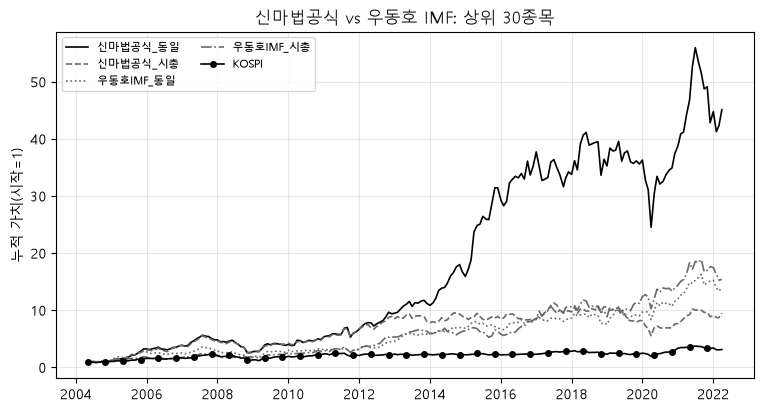

In [5]:
평가.누적그림(R, "신마법공식 vs 우동호 IMF: 상위 30종목");

## 6. 확인: 연도별 단계별 종목 수·빈칸으로 빠진 수·편입 수·WICS 금융 수

In [6]:
pd.concat({k: o["기록"] for k, o in 결과.items()}, axis=1).T

기준일                 2004-04-01  2005-04-01  2006-04-03  2007-04-02  2008-04-01  2009-04-01  2010-04-01  2011-04-01  2012-04-02  2013-04-01  2014-04-01  2015-04-01  2016-04-01  2017-04-03  2018-04-02  2019-04-01  \
신마법공식  가격있음               1754        1756        1801        1872        1952        1981        1966        1970        1971        1930        1923        1954        2051        2111        2163        2238   
       시장                 1754        1756        1801        1872        1952        1981        1966        1970        1971        1930        1923        1954        2051        2111        2163        2238   
       쓰지말것               1753        1755        1800        1871        1951        1980        1965        1969        1970        1929        1923        1954        2051        2111        2163        2238   
       보통주                1573        1584        1634        1707        1781        1810        1806        1816        1819        1782        1783        1827        1933        1993        2045        2122   
       금융업                1490        1507        1559        1632        1705        1735        1725        1717        1727        1710        1717        1735        1806        1868        1855        1920   
       투자기구               1484        1485        1523        1583        1656        1689        1679        1675        1685        1666        1678        1709        1782        1845        1845        1908   
       결산월                1372        1399        1442        1506        1568        1604        1602        1608        1627        1615        1633        1664        1742        1805        1809        1870   
       거래정지               1334        1348        1403        1477        1525        1506        1535        1570        1581        1570        1600        1633        1710        1769        1771        1811   
       빈칸:BP                 3           4           5           5           5           4           6          12           3           4           4           4           4           4           4           5   
       빈칸:GPA                3           4           5           5           5           4           6          12           3           4           4           4           5           5           5           6   
       보유수:동일:상위30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30   
       보유수:시총:상위30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30   
       빈칸으로 빠짐               3           4           5           5           5           4           6          12           3           4           4           4           5           5           5           7   
       편입:상위30              30          30          30          30          30          30          30          30          30          30          30          30          30          30          30          30   
       확인:업종빈칸             368         376         406         428         450         424         433         440         429         415         424         428         458         465         476         461   
       확인:WICS금융             0           0           2           2           3           4           3           3           3           3           4           4           8           5          10          12   
우동호IMF 가격있음               1754        1756        1801        1872        1952        1981        1966        1970        1971        1930        1923        1954        2051        2111        2163        2238   
       시장                 1754        1756        1801        1872        1952        1981        1966        1970        1971        1930        19

## 7. 참고: Novy-Marx(NBER w15940, 2010년 4월판) 표 7 Panel C 설정
원문: 비금융 대형주 500(GP/A·B/M이 모두 있는 종목), 두 순위의 평균, 상위 150 / 중간 200 / 하위 150, 동일가중, 매년 6월 말 리밸런싱, 회계자료는 다음 해 6월 말부터.
우리(2026-11-04 원문 문장대로 고침): 6월 마지막 거래일, 비금융 → GP/A·B/M 둘 다 있음 → 시총 상위 500, **상위 150 / 가운데 200 / 하위 150**(`고르기=("상하N",150)`, p.21), **B/M의 시가는 6개월 전 시가총액**(`BP_6개월`, 각주 3, p.11), **재무는 결산 후 5개월이 지난 회계연도**(`재무시점=("결산후개월",5)`: 각주 4 '다음 해 6월 말부터'. 12월 결산이면 5월 말부터라 6월 마지막 거래일에 들어감. 6개월로 하면 6월 30일이 거래일이 아닌 해에 한 해 늦어짐), 동일·시총가중. 예전 판(3등분·그날 시가·발표일 다음 거래일)과의 차이는 11절 진단 표. 무위험이자율은 기본설정의 콜금리(E11.02.003.001, 원문은 미국 금리).

In [7]:
nm = {**포.기본설정, "이름": "NovyMarx2013_표7C", "시장": ["KS", "KQ"], "기간": ("2004-06", "2022-04"), "기준일": "마지막거래일",
      "리밸런싱": 12, "재무시점": ("결산후개월", 5), "제외": ["금융업", "투자기구", ("지표있음", {"지표들": ["GPA", "BP_6개월"]}), ("시총상위", {"n": 500})],
      "지표": [("GPA", "높게"), ("BP_6개월", "높게")], "합산": "순위합산", "고르기": ("상하N", 150),
      "비중": ["동일", "시총"], "거래비용": dict(수수료=0, 거래세=0, 슬리피지=0)}
o = 포.실행(nm)
Fn = 평가.요인(포.기준일(nm), nm)
N = pd.DataFrame({f"{b}_{g}": o["수익률"][(b, g)] for b, g in o["수익률"]})
N["동일_H-L"], N["시총_H-L"] = N["동일_Q1"] - N["동일_Q3"], N["시총_Q1"] - N["시총_Q3"]
N = N.dropna(how="all")
표N = 평가.성과표(N, Fn, ["동일_H-L", "시총_H-L"])
display(표N)
display(o["기록"].T)
원문 = pd.DataFrame({"월 초과수익(%)": [0.78, 0.64], "t": [3.68, 5.21], "FF3 α(%)": [0.16, 0.39], "FF3 t": [2.69, 3.77]}, index=["High", "H-L"])
우리 = pd.DataFrame({"월 초과수익(%)": 표N.loc[["동일_Q1", "동일_H-L"], "초과평균 α(월)"].to_numpy() * 100,
                   "t": 표N.loc[["동일_Q1", "동일_H-L"], "초과평균 t(OLS)"].to_numpy(),
                   "FF3 α(%)": 표N.loc[["동일_Q1", "동일_H-L"], "FF3 α(월)"].to_numpy() * 100,
                   "FF3 t": 표N.loc[["동일_Q1", "동일_H-L"], "FF3 t(OLS)"].to_numpy()}, index=["High", "H-L"])
NM대조 = pd.concat({"원문(미국 1963-07~2009-12)": 원문, "우리": 우리}, axis=1).swaplevel(axis=1)[list(원문)]
NM대조.to_csv(평가.결과폴더 / "04_NovyMarx대조.csv", encoding="utf-8-sig")  # 결과요약 노트북이 읽음
NM대조

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
동일_Q1,214.0000,10.8976,0.1490,0.1987,0.6784,-0.5062,0.6814,0.0112,2.8651,2.5385,0.0065,3.0486,2.8469,0.0035,2.0961,2.4222,0.0030,1.8284,2.0420,0.9096,0.5235,0.1385,0.0821,0.8393
동일_Q2,214.0000,4.8700,0.1043,0.2162,0.4560,-0.5303,0.3524,0.0082,1.9257,1.7624,0.0029,1.3713,1.4273,0.0014,0.8804,0.9636,0.0010,0.6321,0.6624,1.0350,0.5322,-0.0254,0.0725,0.8744
동일_Q3,214.0000,0.2907,0.0144,0.2448,0.0851,-0.6427,-0.2930,0.0017,0.3593,0.3435,-0.0040,-1.5030,-1.4559,-0.0017,-0.9013,-1.0095,-0.0025,-1.3390,-1.3911,1.1408,0.5536,-0.4224,0.1467,0.8624
시총_Q1,214.0000,10.3123,0.1457,0.1772,0.7203,-0.3581,0.7518,0.0107,3.0419,2.8877,0.0063,3.6910,3.8475,0.0052,2.9802,3.0246,0.0058,3.3094,3.3622,0.8599,0.0007,0.1023,-0.1006,0.7775
시총_Q2,214.0000,2.9531,0.0801,0.1762,0.3868,-0.4116,0.1083,0.0057,1.6335,1.5439,0.0010,0.8177,0.8522,0.0014,1.0288,1.1052,0.0012,0.9227,1.0698,0.9130,0.0336,-0.0431,0.0239,0.8667
시총_Q3,214.0000,1.2036,0.0453,0.2457,0.2068,-0.6335,-0.0836,0.0042,0.8734,0.8490,-0.0019,-0.8028,-0.7925,0.0022,1.0236,1.0078,0.0010,0.4890,0.4724,1.2161,-0.0019,-0.4083,0.2198,0.8341
동일_H-L,214.0000,5.7057,0.1126,0.1178,0.9682,-0.2938,0.1166,0.0095,4.0886,4.1869,0.0106,4.7506,4.5378,0.0052,2.9716,3.0953,0.0056,3.1595,3.4051,-0.2312,-0.0301,0.5609,-0.0646,0.4836
시총_H-L,214.0000,1.8729,0.0610,0.1878,0.4099,-0.4526,-0.0290,0.0064,1.7308,1.8039,0.0081,2.3000,2.3716,0.0030,0.8768,0.8860,0.0047,1.4308,1.4342,-0.3562,0.0026,0.5106,-0.3204,0.2798


기준일,2004-06-30,2005-06-30,2006-06-30,2007-06-29,2008-06-30,2009-06-30,2010-06-30,2011-06-30,2012-06-29,2013-06-28,2014-06-30,2015-06-30,2016-06-30,2017-06-30,2018-06-29,2019-06-28,2020-06-30,2021-06-30
가격있음,1731,1725,1815,1879,1959,1952,1931,1957,1948,1911,1916,1972,2055,2116,2167,2246,2325,2435
시장,1731,1725,1815,1879,1959,1952,1931,1957,1948,1911,1916,1972,2055,2116,2167,2246,2325,2435
쓰지말것,1726,1723,1813,1876,1953,1946,1924,1951,1946,1904,1908,1971,2047,2114,2167,2243,2324,2435
금융업,1626,1632,1722,1785,1861,1854,1825,1837,1842,1818,1822,1852,1905,1975,1946,2036,2118,2214
투자기구,1621,1609,1682,1739,1815,1813,1784,1799,1800,1782,1792,1826,1890,1965,1935,2027,2108,2198
시총상위,500,500,500,500,500,500,500,500,500,500,500,500,500,500,500,500,500,500
빈칸:GPA,30,20,20,22,20,13,13,19,11,13,15,15,14,18,12,11,14,19
빈칸:BP,30,20,20,22,20,13,13,20,11,13,15,15,13,18,12,10,12,13
보유수:동일:Q1,157,160,160,159,160,162,162,160,163,162,162,162,162,161,163,163,162,160
보유수:동일:Q2,156,160,160,159,160,162,162,160,163,162,161,161,162,160,162,163,162,160


월 초과수익(%)                             t                      FF3 α(%)                         FF3 t       
     원문(미국 1963-07~2009-12)     우리 원문(미국 1963-07~2009-12)     우리 원문(미국 1963-07~2009-12)     우리 원문(미국 1963-07~2009-12)     우리
High                 0.7800 1.1246                 3.6800 2.8651                 0.1600 0.3473                 2.6900 2.0961
H-L                  0.6400 0.9508                 5.2100 4.0886                 0.3900 0.5204                 3.7700 2.9716

## 8. 차이 이유 후보
- **신마법공식**: 책 원문이 없어 원문 숫자와 비교할 수 없다. 우동호 IMF와의 차이는 EY 대신 PBR을 쓴 것뿐이다.
- **Novy-Marx 참고판**: 시장·기간(미국 1963~2009 vs 한국), 장부가 정의(원문은 자본 + 이연법인세 − 우선주, 우리는 자본총계(지배)). B/M 6개월 전 시가·150/200/150·재무 시점은 2026-11-04 원문대로 고침(11절).
- **벤치마크**: 신마법공식은 수정주가(배당 미포함)라 코스피 가격지수와 정의가 맞다. Novy-Marx 참고판은 TR 가격이라 정보비율·CAPM α가 배당만큼 높게 나온다.

## 9. 원문과 다르게 한 것
| 항목 | 원문·정의 | 우리 | 이유 |
|---|---|---|---|
| 책 원문(강환국 2017 10장) | 미확인 | 정의는 2차 인용, 나머지는 우동호 IMF 설정 | 책 숫자를 지어내지 않기 |
| PBR 순위 | PBR 낮을수록 좋음 | BP(PBR 역수) 높을수록 좋음 | 자본이 음수인 종목은 PBR이 음수라 '가장 싼 쪽'에 줄 서는 것 막기. 자본이 양수인 종목끼리는 순서가 같음 |
| Novy-Marx 대형주 500 | GP/A·BM 둘 다 있는 비금융 500 | 비금융 → GPA·BP 둘 다 있음(`지표있음`) → 시총 500 | 2026-11-04 원문 순서대로 고침(전에는 시총 500을 먼저 고른 뒤 빈칸 제외) |
| Novy-Marx 묶음 크기 | 150/200/150 | 같음(`상하N`, 2026-11-04 고침. 예전 3등분) | — |
| Novy-Marx B/M 시가 | 6개월 전 시가(각주 3) | 같음(`BP_6개월`, 2026-11-04 고침. 예전 그날 시가) | — |
| Novy-Marx 재무 시점 | 회계자료를 다음 해 6월 말부터(각주 4) | 결산 후 5개월이 지난 회계연도(2026-11-04 고침. 예전 발표일 다음 거래일) | 12월 결산 → 5월 말부터라 6월 마지막 거래일에 씀. 1월 결산은 6월 30일이 거래일인 해만 그해 회계연도가 들어감(한국에 거의 없음, 확인 안 함) |
| Novy-Marx 비금융 | SIC 첫 자리 6 제외 | 거래소 업종 낱말·이름 규칙(`금융업`) + `투자기구` | 한국 자료에 SIC 없음 |
| Novy-Marx 요인·무위험 | Ken French 미국 요인·미국 금리 | DataGuide 한국 요인(3FM.2B3)·콜금리 | 시장이 다름 |
| 상장 구간 | 상장 종목 | 시장구분(CP10000300)이 코스피·코스닥('KS'·'KQ')인 날의 가격만 계산에 씀(`읽기.상장가격`). 원본 값은 그대로 | 통합_확인기록 F2(상장일보다 앞선 가격 = 이전상장 전 시장 가격)·F3(상장폐지 뒤 장외 가격). 회원 결정 2026-11-02 |
| '쓰지 말 것' 칸 | — | README_데이터의 '쓰지 말 것' 구간이 [리밸런싱일, 다음 리밸런싱일]에 걸리면 편입 대상에서 뺌(`종목거르기.쓰지말것`, 항상 `시장` 다음 단계). 직전 12개월 일간수익률에서도 빈칸으로 봄. 값은 그대로 | A008080 2004-01~2013-09(D-05, 재조회 R28도 값 같음), 수정주가 병합·감자 미반영 7칸의 그 달(D27), 배당 포함 가격(TR)을 쓸 때 TR 이상칸 107칸의 앞날~그날(D-06·U3). 회원 결정 2026-11-02 |
| 호텔신라(A008770) FY2023 | — | 매출원가·매출총이익을 빈칸으로 봄 → 그해 GP/A 등에서 제외(값은 그대로, `지표.빈칸으로볼칸`) | 판본마다 값이 다름(R29 재조회는 매출원가 0, 10월 파일은 1,418,625,926천원). 통합_확인기록 F1. 회원 결정 2026-11-02 |
| 끝 날짜 | — | 가격·시장 일간 항목(S·CP 파일)에 값이 있는 마지막 날(`읽기.공통끝`)에서 자름. 재무 일간은 끝나지 않은 회계연도가 빈칸이라 판정에서 뺌 | 통합_확인기록 F6(항목마다 끝 날짜가 다를 수 있음) |
| 코드 재사용 16종목 | — | 재사용 경계를 넘는 수익률을 쓰지 않음(공백 구간이 빈칸이라 끊김, 01 노트북 11절에서 확인). 직전 12개월 상장 판정도 시장구분으로 함 | 통합_확인기록 F5, README_데이터 D-04 |
| 재무 값 뽑기 | — | 달력기준 일간 재무에서 결산일(결산월 이력이 그 달인 달의 마지막 영업일) 값을 그 회계연도 값으로 씀(`읽기.연간재무`). 쓸 수 있는 날은 재무시점 규칙 | 일간 값은 발표 전부터 그 회계연도 값이 들어 있어 그대로 쓰면 미래 정보. 예전 연간 원본과 자산총계 79,657/79,837행 같음(`_검증/일간재무_대조_결과.txt`) |
| 같은 회계연도 두 결산월 | — | 결산일이 늦은 행 | 통합_확인기록 F9(A432320) |


## 11. 원문 차이 진단 (2026-11-04)
- **비교할 수 있는 것은 방향뿐이다.** 원문 표 7 Panel C는 미국 1963-07~2009-12, 우리는 한국 7절 설정 `("2004-06", "2022-04")`(한국 자료로 같은 기간 불가능, D-1). 시장·기간·요인(Ken French 미국 요인 대 DataGuide 한국 요인)·무위험이 모두 달라 숫자 크기는 비교하지 않는다. 판정 기준(돌리기 전에 정함): High 월 초과수익 > 0, H−L > 0, H−L FF3 α > 0의 **부호**가 원문과 같은지.
- 정의 대조:

| 항목 | 원문(쪽) | 우리 본문 |
|---|---|---|
| GP/A | (REVT − COGS)/AT(표 2 설명, p.12) | 매출총이익(M000904007)/자산총계(기말) |
| B/M | 장부가 = 자본 + 이연법인세 − 우선주, 시가는 6개월 전(각주 3, p.11) | 자본총계(지배)/6개월 전 시가총액(장부가 정의는 다름: 이연법인세·우선주 따로 받지 않음) |
| 대형주 500 | 비금융, GP/A·B/M 둘 다 있는 종목 중 시총 상위 500(p.21·22) | 금융업·투자기구 제외 → 둘 다 있음 → 시총 상위 500(유가+코스닥) |
| 비금융 | SIC 첫 자리 6 제외(다른 표 설명) | 거래소 업종 낱말·이름 규칙 + WICS 금융(`금융업`) + `투자기구` |
| 결합·묶음 | 두 순위 평균(p.21), 150/200/150(표 7 Panel C n) | 순위합산(평균과 순서 같음), `상하N` 150 |
| 가중 | 동일(one dollar each) | 동일(본문), 시총(참고) |
| 리밸런싱·재무 | 6월 말 연 1회, 다음 해 6월 말부터(각주 4) | 6월 마지막 거래일, 결산 후 5개월 |

아래 표는 예전 판에서 원문 규칙을 하나씩 더해 간 숫자다(값을 맞추려고 고르지 않음, 규칙은 모두 원문 문장).

In [ ]:
# 예전 판 → 원문 규칙을 하나씩 더함. 마지막 줄 = 7절 본문
단계 = {"예전 판(3등분·그날 시가·발표일)": dict(고르기=("분위", 3), 재무시점=("발표일", 150), bp="BP"),
       "+ 150/200/150": dict(고르기=("상하N", 150), 재무시점=("발표일", 150), bp="BP"),
       "+ B/M 6개월 전 시가": dict(고르기=("상하N", 150), 재무시점=("발표일", 150), bp="BP_6개월"),
       "+ 재무 결산 후 5개월(= 7절 본문)": dict(고르기=("상하N", 150), 재무시점=("결산후개월", 5), bp="BP_6개월")}
rows = {}
for k, d in 단계.items():
    c = {**nm, "비중": ["동일"], "고르기": d["고르기"], "재무시점": d["재무시점"], "지표": [("GPA", "높게"), (d["bp"], "높게")],
         "제외": ["금융업", "투자기구", ("지표있음", {"지표들": ["GPA", d["bp"]]}), ("시총상위", {"n": 500})]}
    r = 포.실행(c)["수익률"]["동일"]
    x = pd.DataFrame({"High": r["Q1"], "H-L": r["Q1"] - r["Q3"]}).dropna(how="all")
    t = 평가.성과표(x, Fn, ["H-L"])
    rows[k] = {"High 월 초과(%)": t.loc["High", "초과평균 α(월)"] * 100, "High t": t.loc["High", "초과평균 t(OLS)"],
               "H-L 월(%)": t.loc["H-L", "초과평균 α(월)"] * 100, "H-L t": t.loc["H-L", "초과평균 t(OLS)"],
               "H-L FF3 α(%)": t.loc["H-L", "FF3 α(월)"] * 100, "H-L FF3 t": t.loc["H-L", "FF3 t(OLS)"]}
rows["원문 표 7 Panel C(미국)"] = {"High 월 초과(%)": 0.78, "High t": 3.68, "H-L 월(%)": 0.64, "H-L t": 5.21, "H-L FF3 α(%)": 0.39, "H-L FF3 t": 3.77}
진단 = pd.DataFrame(rows).T
부호 = np.sign(진단[["High 월 초과(%)", "H-L 월(%)", "H-L FF3 α(%)"]])
진단["부호가 원문과 같은 칸(3칸 중)"] = (부호 == 부호.iloc[-1]).sum(axis=1)
진단

### 원문 차이 진단 요약
| 원인 | 근거 | 바꾼 뒤 숫자 | 원문 | 남은 차이 |
|---|---|---|---|---|
| 묶음 크기 | 표 7 Panel C n 150/200/150 | 위 표 '+ 150/200/150' 줄 | High 0.78 [3.68], H−L 0.64 [5.21], H−L FF3 α 0.39 [3.77] | 시장·기간이 달라 크기는 비교 안 함, 부호 칸만 |
| B/M 시가 시점 | 각주 3 'lagged six months' | '+ B/M 6개월 전 시가' 줄 | 같음 | 같음 |
| 재무 시점 | 각주 4 다음 해 6월 말 | '+ 재무 결산 후 5개월' 줄(본문) | 같음 | 같음 |
| 장부가 정의 | 각주 3 자본 + 이연법인세 − 우선주 | 바꿔 보지 않음(이연법인세·우선주 자본 항목을 받지 않음, `_검증/추가로_받을것.md` 7절) | — | 남음 |
| 시장·기간·요인 | 미국 1963~2009, Ken French 요인 | 바꿀 수 없음 | — | 남음(방향만 비교) |

숫자는 위 코드 출력이 정본이다. 7절 본문은 원문 문장이 받치는 세 규칙(150/200/150, 6개월 전 시가, 다음 해 6월 말)으로 바꿨다.

## 10. 요약표용 저장
4절 상위 30 포트폴리오(EW·VW)의 월수익률을 `결과_월수익률/`에 남긴다.

In [8]:
R2 = R.drop(columns="KOSPI")
R2.columns = pd.MultiIndex.from_tuples([tuple(c.rsplit("_", 1)) for c in R2])
평가.저장(R2, F, "04_신마법공식", 이상값={tuple(c.rsplit("_", 1)): n for c, n in 표["이상값 보유"].items() if c != "KOSPI"})
list(R2)

[('신마법공식', '동일'), ('신마법공식', '시총'), ('우동호IMF', '동일'), ('우동호IMF', '시총')]